# Patch Tuesday Analysis

Pull Microsoft security updates directly from the MSRC API and analyze
exploitation status, severity trends, and impact types across months.
The MSRC API requires no authentication.

In [1]:
from vulnflow import VulnDataset

ds = VulnDataset.from_msrc(start="2025-01", end="2025-04")
print(f"{len(ds):,} CVEs across Jan-Apr 2025")

MSRCExtractor(2025-01..2025-04):   0%|          | 0.00/4.00 [00:00<?, ?months/s]

1,294 CVEs across Jan-Apr 2025


In [2]:
from vulnflow.transforms.enrichers.epss import EPSSEnricher
from vulnflow.transforms.flatten.cvss import CVSSFlattenTransform
from vulnflow.transforms.flatten.epss import EPSSFlattenTransform
from vulnflow.transforms.flatten.msrc import MSRCFlattenTransform

ds.transform([
    CVSSFlattenTransform(),
    MSRCFlattenTransform(),
    EPSSEnricher(),
    EPSSFlattenTransform(),
])

df = ds.to_pandas()
print(f"{len(df.columns)} columns after enrichment")
df.head(3)

Enriching & transforming:   0%|          | 0/4 [00:00<?, ?transforms/s]

35 columns after enrichment


,id,cve_id,description,nvd_published_at,nvd_modified_at,nvd_status,cvss_version,cvss_base_score,cvss_base_severity,cvss_source,...,epss_bucket,capecs,stride_threats,tags,metadata,msrc_exploited,msrc_publicly_disclosed,msrc_impact,msrc_max_severity,msrc_month_id
0,b87a3d32-dd9f-4a8c-b4a6-67f1b9d1a058,CVE-2022-49043,NaN,NaT,NaT,None,3.1,8.1,HIGH,microsoft,...,very_low,[],[],{},"{""msrc"":{""month_id"":""2025-Jan"",""title"":""xmlXIn...",False,False,NaN,Critical,2025-Jan
1,17803cfc-dfdd-49ba-ab03-9e5506125b19,CVE-2024-10846,NaN,NaT,NaT,None,3.1,5.9,MEDIUM,microsoft,...,very_low,[],[],{},"{""msrc"":{""month_id"":""2025-Jan"",""title"":""Excess...",False,False,NaN,Moderate,2025-Jan
2,e62fd615-21eb-4dd0-846d-19ad2664767b,CVE-2024-11187,NaN,NaT,NaT,None,3.1,7.5,HIGH,microsoft,...,medium,[],[],{},"{""msrc"":{""month_id"":""2025-Jan"",""title"":""Many r...",False,False,NaN,Important,2025-Jan


## Actively Exploited CVEs

These are flagged "Exploitation Detected" by Microsoft — the highest-priority items.

In [3]:
exploited = df[df["msrc_exploited"] == True].sort_values("cvss_base_score", ascending=False)
print(f"{len(exploited)} actively exploited CVEs")
exploited[["cve_id", "msrc_month_id", "cvss_base_score", "msrc_max_severity",
           "msrc_impact", "epss_probability", "description"]]

13 actively exploited CVEs


,cve_id,msrc_month_id,cvss_base_score,msrc_max_severity,msrc_impact,epss_probability,description
693,CVE-2025-24989,2025-Feb,8.2,Critical,Elevation of Privilege,0.01622,<p>An improper access control vulnerability in...
270,CVE-2025-21333,2025-Jan,7.8,Important,Elevation of Privilege,0.10066,NaN
271,CVE-2025-21334,2025-Jan,7.8,Important,Elevation of Privilege,0.01573,NaN
272,CVE-2025-21335,2025-Jan,7.8,Important,Elevation of Privilege,0.01401,NaN
637,CVE-2025-21418,2025-Feb,7.8,Important,Elevation of Privilege,0.02132,NaN
867,CVE-2025-24985,2025-Mar,7.8,Important,Remote Code Execution,0.0389,<p>Integer overflow or wraparound in Windows F...
873,CVE-2025-24993,2025-Mar,7.8,Important,Remote Code Execution,0.02216,<p>Heap-based buffer overflow in Windows NTFS ...
1194,CVE-2025-29824,2025-Apr,7.8,Important,Elevation of Privilege,0.19254,<p>Use after free in Windows Common Log File S...
636,CVE-2025-21391,2025-Feb,7.1,Important,Elevation of Privilege,0.02284,NaN
865,CVE-2025-24983,2025-Mar,7.0,Important,Elevation of Privilege,0.0187,<p>Use after free in Windows Win32 Kernel Subs...


## Monthly Severity Breakdown

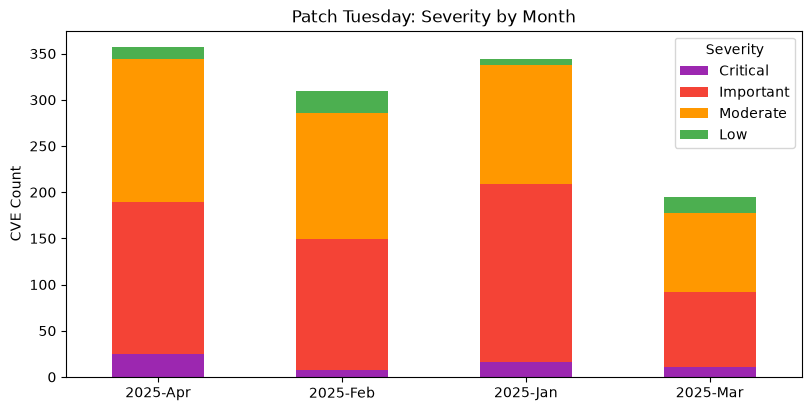

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

severity_order = ["Critical", "Important", "Moderate", "Low"]
colors = {"Critical": "#9c27b0", "Important": "#f44336", "Moderate": "#ff9800", "Low": "#4caf50"}

pivot = (
    df.groupby(["msrc_month_id", "msrc_max_severity"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=severity_order)
    .fillna(0)
    .astype(int)
)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
pivot.plot.bar(ax=ax, stacked=True, color=[colors[s] for s in pivot.columns])
ax.set_title("Patch Tuesday: Severity by Month")
ax.set_ylabel("CVE Count")
ax.set_xlabel("")
ax.legend(title="Severity")
plt.xticks(rotation=0)
plt.show()

## Impact Type Distribution

What kinds of vulnerabilities is Microsoft patching?

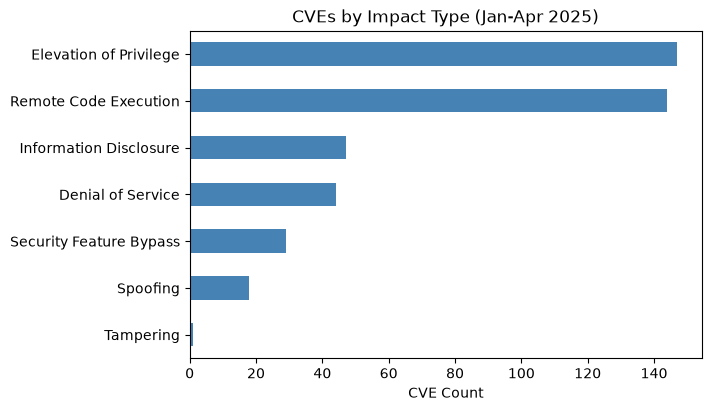

In [5]:
impact_counts = df["msrc_impact"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
impact_counts.plot.barh(ax=ax, color="steelblue")
ax.set_title("CVEs by Impact Type (Jan-Apr 2025)")
ax.set_xlabel("CVE Count")
ax.set_ylabel("")
ax.invert_yaxis()
plt.show()

## Exploitation Risk Matrix

Cross-tabulate exploitation status against impact type to see where
active exploitation concentrates.

In [6]:
risk = pd.crosstab(
    df["msrc_impact"],
    df["msrc_exploited"].map({True: "Exploited", False: "Not Exploited"}),
    margins=True,
)
risk.sort_values("All", ascending=False)

msrc_exploited,Exploited,Not Exploited,All
msrc_impact,,,
All,13,417,430
Elevation of Privilege,8,139,147
Remote Code Execution,2,142,144
Information Disclosure,2,45,47
Denial of Service,0,44,44
Security Feature Bypass,1,28,29
Spoofing,0,18,18
Tampering,0,1,1


## EPSS vs CVSS — Microsoft Vulnerabilities

Quadrant lines at CVSS = 7 and EPSS = 0.1. Upper-right = high severity
and high exploitation probability. Red dots are actively exploited.

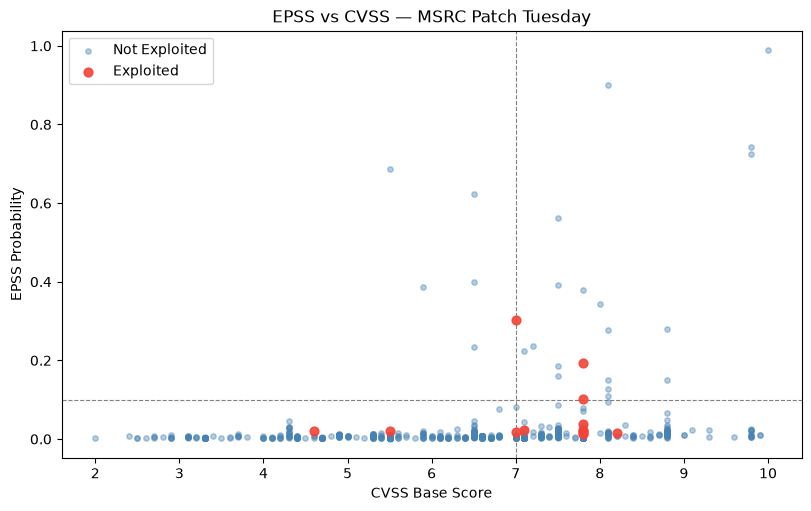

In [7]:
plot_df = df.dropna(subset=["cvss_base_score", "epss_probability"])

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

safe = plot_df[plot_df["msrc_exploited"] != True]
expl = plot_df[plot_df["msrc_exploited"] == True]

ax.scatter(safe["cvss_base_score"], safe["epss_probability"],
           alpha=0.4, s=15, color="steelblue", label="Not Exploited")
ax.scatter(expl["cvss_base_score"], expl["epss_probability"],
           alpha=0.9, s=40, color="#f44336", label="Exploited", zorder=5)

ax.axvline(7, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.1, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("CVSS Base Score")
ax.set_ylabel("EPSS Probability")
ax.set_title("EPSS vs CVSS — MSRC Patch Tuesday")
ax.legend()
plt.show()

## Monthly Trend Summary

In [8]:
summary = (
    df.groupby("msrc_month_id")
    .agg(
        total=("cve_id", "count"),
        critical=("msrc_max_severity", lambda x: (x == "Critical").sum()),
        exploited=("msrc_exploited", lambda x: (x == True).sum()),
        disclosed=("msrc_publicly_disclosed", lambda x: (x == True).sum()),
        avg_cvss=("cvss_base_score", "mean"),
    )
    .round(1)
)
summary

,total,critical,exploited,disclosed,avg_cvss
msrc_month_id,,,,,
2025-Apr,375,25,1,0,6.510833
2025-Feb,329,8,3,2,6.402357
2025-Jan,369,16,3,5,6.668675
2025-Mar,221,11,6,1,6.269898


## Save

Write to Parquet for reuse without re-downloading.

In [9]:
ds.to_parquet("../data/msrc-2025-q1.parquet")
print("Saved to ../data/msrc-2025-q1.parquet")

Saved to ../data/msrc-2025-q1.parquet
